# 03 - Imputation comparison, PCA and models
**Question**: which imputation (mean / median / KNN), with or without PCA, and which model (KNN, decision tree, random forest) classify planets vs false positives best?

**Protocol (to avoid leakage and over-optimism)**
1. Split **by star** (`kepid`): 80% train / 20% test, the test set is touched once at the end.
2. Model selection with 5-fold `StratifiedGroupKFold` on the train set only.
3. Every preprocessing step (log, scaling, imputation, PCA) lives **inside** the pipeline, so it is fitted on the training part of each fold only.
4. Metrics: F1 and ROC-AUC (the classes are imbalanced, 33% positive).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score, confusion_matrix, RocCurveDisplay, ConfusionMatrixDisplay
SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
d = pd.read_csv("../data/processed/koi_binary_clean.csv")
features = [c for c in d.columns if c not in ("kepid", "target")]
X, y, groups = d[features], d["target"], d["kepid"]
print(X.shape, "positive rate:", round(y.mean(), 3))

(7197, 13) positive rate: 0.327


In [2]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr, te = next(gss.split(X, y, groups))
Xtr, Xte, ytr, yte, gtr = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], groups.iloc[tr]
print("train:", len(Xtr), "test:", len(Xte), "| stars shared between sets:", len(set(groups.iloc[tr]) & set(groups.iloc[te])))
print("positive rate train/test:", round(ytr.mean(), 3), round(yte.mean(), 3))

train: 5764 test: 1433 | stars shared between sets: 0
positive rate train/test: 0.327 0.329


## Pipeline
`log1p` on heavily skewed positive features, then standardisation (NaN-safe), then **imputation** (so KNN works on comparable scales), then optional **PCA** (95% variance), then the model.

In [3]:
skewed = [c for c in ["koi_period", "koi_depth", "koi_prad", "koi_insol", "koi_model_snr", "koi_srad", "koi_teq"] if c in features]
idx = [features.index(c) for c in skewed]
imputers = {"mean": lambda: SimpleImputer(strategy="mean"), "median": lambda: SimpleImputer(strategy="median"),
            "knn": lambda: KNNImputer(n_neighbors=5)}
models = {"KNN": lambda: KNeighborsClassifier(n_neighbors=15),
          "Decision tree": lambda: DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=SEED),
          "Random forest": lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)}
def build(imp, model, pca):
    steps = [("log", ColumnTransformer([("l", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), idx)], remainder="passthrough")),
             ("scale", StandardScaler()), ("impute", imputers[imp]())]
    if pca: steps.append(("pca", PCA(n_components=0.95, random_state=SEED)))
    steps.append(("model", models[model]()))
    return Pipeline(steps)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

## Cross-validated comparison (train set only): 3 imputations x 3 models x {no PCA, PCA}

In [4]:
rows = []
for imp in imputers:
    for m in models:
        for pca in (False, True):
            r = cross_validate(build(imp, m, pca), Xtr, ytr, groups=gtr, cv=cv, scoring=["f1", "roc_auc"], n_jobs=1)
            rows.append({"imputation": imp, "model": m, "pca": pca, "f1_mean": r["test_f1"].mean(), "f1_std": r["test_f1"].std(),
                         "auc_mean": r["test_roc_auc"].mean(), "auc_std": r["test_roc_auc"].std()})
cvres = pd.DataFrame(rows).round(4)
cvres.to_csv("../results/cv_results.csv", index=False)
cvres.sort_values("f1_mean", ascending=False)

,imputation,model,pca,f1_mean,f1_std,auc_mean,auc_std
10,median,Random forest,False,0.8846,0.0072,0.9760,0.0028
4,mean,Random forest,False,0.8842,0.0058,0.9760,0.0033
16,knn,Random forest,False,0.8755,0.0036,0.9721,0.0023
2,mean,Decision tree,False,0.8510,0.0096,0.9418,0.0071
0,mean,KNN,False,0.8472,0.0090,0.9556,0.0031
14,knn,Decision tree,False,0.8431,0.0087,0.9414,0.0063
6,median,KNN,False,0.8414,0.0087,0.9541,0.0033
8,median,Decision tree,False,0.8384,0.0117,0.9380,0.0049
5,mean,Random forest,True,0.8367,0.0095,0.9557,0.0035
12,knn,KNN,False,0.8365,0.0124,0.9516,0.0040


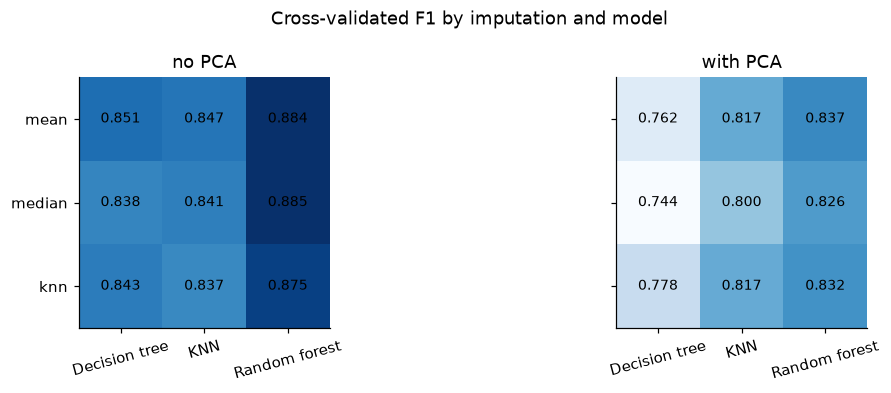

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, pca in zip(ax, (False, True)):
    p = cvres[cvres.pca == pca].pivot(index="imputation", columns="model", values="f1_mean").loc[["mean", "median", "knn"]]
    im = a.imshow(p.values, cmap="Blues", vmin=cvres.f1_mean.min(), vmax=cvres.f1_mean.max())
    a.set_xticks(range(3), p.columns, rotation=15); a.set_yticks(range(3), p.index); a.set_title("with PCA" if pca else "no PCA")
    for i in range(3):
        for j in range(3): a.text(j, i, f"{p.values[i, j]:.3f}", ha="center", va="center", fontsize=9)
fig.suptitle("Cross-validated F1 by imputation and model"); plt.tight_layout(); plt.savefig("../results/figures/cv_f1_heatmap.png"); plt.show()

## PCA: how many components are needed?

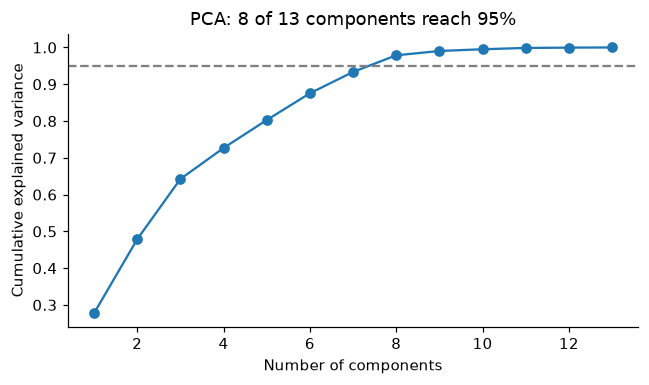

components for 95%: 8


In [6]:
pre = build("median", "KNN", False); pre.steps.pop()          # preprocessing only
Z = pre.fit_transform(Xtr)
ev = PCA().fit(Z).explained_variance_ratio_.cumsum()
n95 = int(np.argmax(ev >= .95)) + 1
plt.figure(figsize=(6, 3.6)); plt.plot(range(1, len(ev) + 1), ev, "o-"); plt.axhline(.95, ls="--", c="grey")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance"); plt.title(f"PCA: {n95} of {len(ev)} components reach 95%")
plt.tight_layout(); plt.savefig("../results/figures/pca_variance.png"); plt.show(); print("components for 95%:", n95)

## Final evaluation on the held-out test set
For each model we take its best configuration according to **CV F1** (never the test set), refit on the full train set, and evaluate once.

In [7]:
best = cvres.loc[cvres.groupby("model")["f1_mean"].idxmax()]
final, fitted, rows = {}, {}, []
for _, b in best.iterrows():
    pipe = build(b.imputation, b.model, bool(b.pca)).fit(Xtr, ytr)
    p = pipe.predict_proba(Xte)[:, 1]; pred = (p >= .5).astype(int)
    fitted[b.model] = (pipe, p, pred)
    rows.append({"model": b.model, "imputation": b.imputation, "pca": bool(b.pca), "cv_f1": b.f1_mean,
                 "test_f1": f1_score(yte, pred), "test_auc": roc_auc_score(yte, p),
                 "precision": precision_score(yte, pred), "recall": recall_score(yte, pred)})
test_res = pd.DataFrame(rows).round(4); test_res.to_csv("../results/test_results.csv", index=False); test_res

,model,imputation,pca,cv_f1,test_f1,test_auc,precision,recall
0,Decision tree,mean,False,0.8510,0.8458,0.9403,0.8113,0.8835
1,KNN,mean,False,0.8472,0.8492,0.9567,0.7985,0.9068
2,Random forest,median,False,0.8846,0.8819,0.9732,0.8782,0.8856


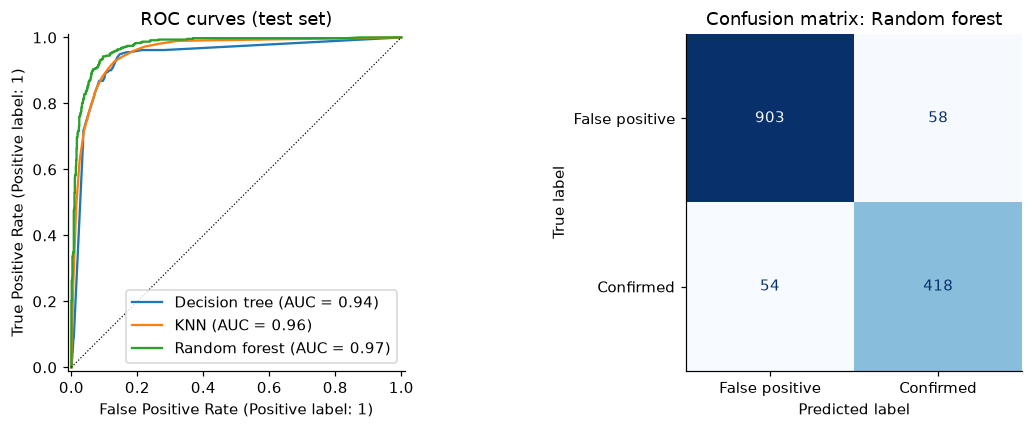

Best model on test: Random forest


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, (pipe, p, pred) in fitted.items(): RocCurveDisplay.from_predictions(yte, p, name=name, ax=ax[0])
ax[0].plot([0, 1], [0, 1], "k:", lw=.8); ax[0].set_title("ROC curves (test set)")
bn = test_res.sort_values("test_f1").iloc[-1].model
ConfusionMatrixDisplay(confusion_matrix(yte, fitted[bn][2]), display_labels=["False positive", "Confirmed"]).plot(ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title(f"Confusion matrix: {bn}"); plt.tight_layout(); plt.savefig("../results/figures/test_roc_confusion.png"); plt.show()
print("Best model on test:", bn)

## What drives the predictions? (permutation importance, Random forest)

/home/marouen/kepler-exoplanet-classification/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/marouen/kepler-exoplanet-classification/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/marouen/kepler-exoplanet-classification/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  w

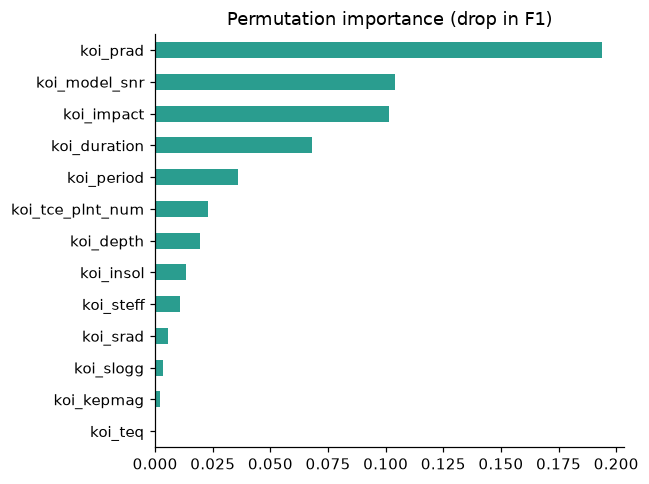

koi_prad         0.193800
koi_model_snr    0.104244
koi_impact       0.101605
koi_duration     0.068222
koi_period       0.035800
dtype: float64

In [9]:
from sklearn.inspection import permutation_importance
rf_pipe = fitted["Random forest"][0]
pi = permutation_importance(rf_pipe, Xte, yte, scoring="f1", n_repeats=10, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=features).sort_values()
imp.plot.barh(figsize=(6, 4.5), color="#2a9d8f"); plt.title("Permutation importance (drop in F1)")
plt.tight_layout(); plt.savefig("../results/figures/feature_importance.png"); plt.show()
imp.sort_values(ascending=False).round(4).rename("importance").rename_axis("feature").to_csv("../results/feature_importance.csv"); imp.sort_values(ascending=False).head(5)

## Error analysis

In [10]:
pipe, p, pred = fitted[bn]
err = Xte.copy(); err["kepid"] = groups.iloc[te].values; err["true"] = yte.values; err["proba_confirmed"] = p.round(3); err["pred"] = pred
wrong = err[err.true != err.pred].copy()
wrong["error_type"] = np.where(wrong.pred == 1, "false alarm kept as planet (FP)", "planet missed (FN)")
wrong.sort_values("proba_confirmed").to_csv("../results/test_errors.csv", index=False)
print(wrong.error_type.value_counts().to_string())
print("\nMedian transit SNR  - errors:", round(wrong.koi_model_snr.median(), 1), "| correct:", round(err[err.true == err.pred].koi_model_snr.median(), 1))
print("Median planet radius - errors:", round(wrong.koi_prad.median(), 2), "| correct:", round(err[err.true == err.pred].koi_prad.median(), 2))
wrong.head(8)

error_type
false alarm kept as planet (FP)    58
planet missed (FN)                 54

Median transit SNR  - errors: 22.4 | correct: 38.1
Median planet radius - errors: 1.67 | correct: 2.97


,koi_period,koi_impact,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_model_snr,koi_tce_plnt_num,koi_steff,koi_slogg,koi_srad,koi_kepmag,kepid,true,proba_confirmed,pred,error_type
19,2.696371,0.044,3.61290,398.0,1.58,1066.0,305.34,48.2,1.0,4989.0,4.504,0.819,15.269,10583180,0,0.664,1,false alarm kept as planet (FP)
93,2.990254,0.014,5.41400,589.0,1.70,918.0,168.45,48.5,1.0,4667.0,4.578,0.731,15.842,3838486,0,0.592,1,false alarm kept as planet (FP)
111,7.919369,0.733,3.31480,15100.0,10.34,814.0,104.00,389.0,1.0,5690.0,4.588,0.776,15.805,5077629,0,0.636,1,false alarm kept as planet (FP)
178,20.545237,0.950,2.51700,219.0,2.41,742.0,71.57,18.5,1.0,5670.0,4.206,1.264,12.003,11869052,0,0.892,1,false alarm kept as planet (FP)
249,38.478766,0.003,5.04169,23500.0,13.26,484.0,13.01,1077.8,1.0,5510.0,4.539,0.879,13.779,11449844,1,0.495,0,planet missed (FN)
306,18.925372,0.806,3.98350,641.0,13.92,1171.0,443.58,41.0,1.0,4941.0,3.317,4.885,14.604,3218908,1,0.251,0,planet missed (FN)
311,4.618768,0.766,5.99570,4400.0,7.48,1170.0,442.78,270.1,1.0,6013.0,4.381,1.033,13.652,11673674,0,0.578,1,false alarm kept as planet (FP)
312,2.785821,0.893,3.55990,68.9,1.69,1784.0,2388.98,53.6,1.0,6202.0,4.026,1.733,8.224,3632418,1,0.281,0,planet missed (FN)


## Conclusions
- **Random forest is the best model** (CV F1 0.885, test F1 0.882, test AUC 0.973). KNN and the decision tree are about 3 points of F1 lower.
- **Imputation barely matters**: mean and median give the same result (0.884 vs 0.885), KNN imputation is slightly worse (0.876). The differences are of the order of the fold-to-fold standard deviation (about 0.006), so none of them is a clear winner. Only 3-4% of values are missing.
- **PCA hurts** (random forest drops from 0.885 to 0.837 F1; the tree drops by about 8 points): 8 components keep 95% of the variance but mix features that the trees use separately, and the discriminative information is not in the largest-variance directions.
- **Main drivers**: planet radius (`koi_prad`), transit signal-to-noise (`koi_model_snr`), impact parameter and transit duration. This is physically sensible: very large "planets" are usually stars or eclipsing binaries.
- **Errors** (58 false alarms kept, 54 planets missed) concentrate on **small, low signal-to-noise objects** (median SNR 22 vs 38 for correct predictions; median radius 1.7 vs 3.0 Earth radii), where the signal is weak.
- **Limits**: a single hold-out of 1,433 objects (about +/-1 point of uncertainty), no hyperparameter search, and the vetting flags (`koi_fpflag_*`, `koi_score`) were deliberately excluded. Models that include them reach higher scores but are not predicting independently of the label.